# SmartStay AI — Análisis Exploratorio de Datos (EDA)

**Reto 1 · Curso de Especialización en Inteligencia Artificial y Big Data**  
**Asignatura:** Sistemas de Aprendizaje Automático (SAA)

## 1. Introducción y objetivos

SmartStay AI desarrolla un modelo de **regresión supervisada** para estimar el precio por noche (`price`) de alojamientos turísticos en España y apoyar decisiones comerciales.

Este notebook estudia la calidad y distribución de los datos, documenta las decisiones de tratamiento de valores ausentes, explora relaciones entre variables y prepara los conjuntos de entrenamiento y prueba. El modelado y la comparación de algoritmos se desarrollan en el notebook `02_modelos.ipynb`.

**Dataset de origen:** `listings_espana_unificado.csv` (109.437 registros y 20 columnas). El análisis parte del dataset completo; el estudio posterior de modelos incluye un segmento especializado de precios de hasta 500 €.

> **Nota de reproducción:** Se han conservado las celdas de código y sus salidas originales, reorganizando los bloques para facilitar la lectura. Las salidas existentes corresponden a ejecuciones previas; para verificar el resultado completo, ejecuta las celdas en orden desde un kernel reiniciado y con las rutas de datos disponibles.


## 2. Carga y descripción del dataset

Se importa el archivo original y se revisan dimensiones, columnas, tipos de datos y significado de las variables.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset unificado
df = pd.read_csv(
    "../data/raw/listings_espana_unificado.csv",
    low_memory=False
)

# Mostrar dimensiones
print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])

# Mostrar las primeras 5 filas
display(df.head())

Número de filas: 109437
Número de columnas: 20


,zona,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,Barcelona,18674,Huge flat for 8 people close to Sagrada Familia,71615,1462508358342835057,Maria Y Mireia Y Ana Barcelona4Seasons,Eixample,la Sagrada Família,41.40556,2.17262,Entire home/apt,274.0,1.0,60,2026-07-20,0.37,21,162,8,Spain - National registration number<br />ESFC...
1,Barcelona,23197,CCIB Forum • Spacious 3BR • Large Balcony,90417,1462509351463595774,Marnie,Sant Martí,el Besòs i el Maresme,41.41243,2.21975,Entire home/apt,408.0,3.0,102,2026-09-07,0.54,1,128,11,Spain - National registration number<br />ESFC...
2,Barcelona,34981,VIDRE HOME PLAZA REAL on LAS RAMBLAS,73163,1462508447204147103,Andres,Ciutat Vella,el Barri Gòtic,41.37978,2.17623,Entire home/apt,546.0,1.0,314,2026-09-13,1.62,2,316,43,Spain - National registration number<br />ESFC...
3,Barcelona,36763,In front of the beach,158596,1462511238526662756,Ester,Ciutat Vella,la Barceloneta,41.38043,2.19094,Private room,44.0,31.0,108,2023-12-13,0.59,1,77,0,NaN
4,Barcelona,40983,Architect's Loft near Gaudí & Passeig de Gràcia,177617,1462511822388459344,Joaquin Fernandez,Eixample,la Dreta de l'Eixample,41.39631,2.16832,Entire home/apt,187.0,1.0,464,2026-09-13,2.50,5,283,62,Barcelona - Regional registration number<br />...


In [2]:
# Información de las columnas y valores no nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 109437 entries, 0 to 109436
Data columns (total 20 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   zona                            109437 non-null  str    
 1   id                              109437 non-null  int64  
 2   name                            109437 non-null  str    
 3   host_id                         109437 non-null  int64  
 4   host_profile_id                 109437 non-null  int64  
 5   host_name                       109437 non-null  str    
 6   neighbourhood_group             60936 non-null   str    
 7   neighbourhood                   109437 non-null  str    
 8   latitude                        109437 non-null  float64
 9   longitude                       109437 non-null  float64
 10  room_type                       109437 non-null  str    
 11  price                           89614 non-null   float64
 12  minimum_nights             

### Tabla descriptiva de las variables del dataset

In [3]:
# Tabla descriptiva de las variables del dataset

tabla_variables = pd.DataFrame({
    "Variable": df.columns,
    "Tipo": df.dtypes.astype(str).values,
    "Nulos": df.isnull().sum().values,
    "% Nulos": (df.isnull().mean() * 100).round(2).values,
    "Valores únicos": df.nunique().values
})

display(tabla_variables)

,Variable,Tipo,Nulos,% Nulos,Valores únicos
0,zona,str,0,0.00,9
1,id,int64,0,0.00,109437
2,name,str,0,0.00,102134
3,host_id,int64,0,0.00,38390
4,host_profile_id,int64,0,0.00,38390
5,host_name,str,0,0.00,11767
6,neighbourhood_group,str,48501,44.32,64
7,neighbourhood,str,0,0.00,874
8,latitude,float64,0,0.00,72403
9,longitude,float64,0,0.00,73489


### Descripción y selección de variables del dataset

El dataset original contiene **109.437 registros y 20 variables**, procedentes de anuncios de alojamientos turísticos en nueve zonas de España.

La variable objetivo del proyecto es `price`, que representa el precio por noche del alojamiento.

#### Diccionario de variables

| Variable | Descripción | Tipo | % nulos | Uso en ML |
|---|---|---|---:|---|
| `zona` | Zona geográfica de procedencia del anuncio | Categórica | 0 % | Sí |
| `id` | Identificador único del alojamiento | Numérica (ID) | 0 % | No |
| `name` | Nombre o título del anuncio | Texto | 0 % | No |
| `host_id` | Identificador del anfitrión | Numérica (ID) | 0 % | No |
| `host_profile_id` | Identificador del perfil del anfitrión | Numérica (ID) | 0 % | No |
| `host_name` | Nombre del anfitrión | Texto | 0 % | No |
| `neighbourhood_group` | Agrupación administrativa de barrios o distritos | Categórica | 44,32 % | No |
| `neighbourhood` | Barrio del alojamiento | Categórica | 0 % | No |
| `latitude` | Latitud geográfica | Numérica | 0 % | Sí |
| `longitude` | Longitud geográfica | Numérica | 0 % | Sí |
| `room_type` | Tipo de alojamiento o habitación | Categórica | 0 % | Sí |
| `price` | Precio por noche del alojamiento | Numérica | 18,11 % | Objetivo |
| `minimum_nights` | Número mínimo de noches exigido | Numérica | 9,82 % | Sí |
| `number_of_reviews` | Número total de reseñas | Numérica | 0 % | Sí |
| `last_review` | Fecha de la última reseña | Fecha (almacenada como texto) | 14,47 % | No |
| `reviews_per_month` | Media de reseñas mensuales | Numérica | 14,47 % | Sí |
| `calculated_host_listings_count` | Número de alojamientos del anfitrión | Numérica | 0 % | Sí |
| `availability_365` | Días disponibles durante los próximos 365 días | Numérica | 0 % | Sí |
| `number_of_reviews_ltm` | Reseñas recibidas durante los últimos 12 meses | Numérica | 0 % | Sí |
| `license` | Identificador de licencia turística | Texto | 26,06 % | No |

#### Justificación de las variables descartadas

Se excluyen los identificadores (`id`, `host_id`, `host_profile_id`) porque no representan directamente características generales del alojamiento y podrían introducir relaciones artificiales.

Las variables `name` y `host_name` se descartan porque contienen texto libre que requeriría técnicas adicionales de procesamiento de lenguaje natural.

`neighbourhood_group` se excluye debido a su elevado porcentaje de valores nulos (44,32 %) y a las diferencias de estructura territorial entre zonas.

`neighbourhood` se descarta en esta primera versión porque contiene 874 categorías distintas. Se prioriza utilizar las coordenadas geográficas para representar la ubicación.

`last_review` se excluye porque su información temporal no se incorpora al modelo actual y parte de su información está relacionada con otras variables de reseñas.

`license` se descarta por su carácter identificativo y su porcentaje de valores ausentes (26,06 %).

#### Tratamiento de los valores nulos

- **`price`:** se eliminan los registros sin precio, porque no es posible entrenar un modelo supervisado sin conocer la variable objetivo.
- **`minimum_nights`:** se aplica imputación mediante la mediana dentro del Pipeline de preprocesamiento.
- **`reviews_per_month`:** se sustituyen los valores ausentes por cero, como aproximación para alojamientos sin actividad de reseñas registrada.
- **`estancia_larga`:** se crea una nueva variable categórica a partir de `minimum_nights`, que identifica los alojamientos con una estancia mínima de 30 noches. Los valores ausentes se conservan inicialmente y posteriormente se imputan dentro del Pipeline.

#### Conclusión

La selección final utiliza **11 variables predictoras**: ocho numéricas y tres categóricas, incluyendo la nueva variable `estancia_larga`.

Esta selección permite combinar información sobre ubicación, características del alojamiento, disponibilidad y actividad de reseñas, manteniendo un preprocesamiento reproducible mediante un Pipeline de scikit-learn.

## 3. Calidad de los datos

Se identifican valores ausentes, registros duplicados y valores fuera de los rangos esperados antes de preparar el dataset.


In [4]:
# Análisis de valores nulos

nulos = pd.DataFrame({
    "Nulos": df.isnull().sum(),
    "Porcentaje (%)": (df.isnull().sum() / len(df) * 100).round(2)
})

# Mostrar únicamente las columnas con valores nulos
nulos = nulos[nulos["Nulos"] > 0]

# Ordenar de mayor a menor porcentaje
nulos = nulos.sort_values("Porcentaje (%)", ascending=False)

display(nulos)

,Nulos,Porcentaje (%)
neighbourhood_group,48501,44.32
license,28521,26.06
price,19823,18.11
last_review,15841,14.47
reviews_per_month,15841,14.47
minimum_nights,10745,9.82


### ¿Qué hacemos con estos nulos?

El dataset contiene **109.437 registros y 20 columnas**, de las cuales 6 presentan valores ausentes.

Antes de entrenar los modelos, debemos definir una estrategia de tratamiento de los nulos según la naturaleza y utilidad de cada variable.

| Variable | % Nulos | Tratamiento propuesto |
|---|---:|---|
| `neighbourhood_group` | 44,32 % | Sustituir los nulos por la categoría `"Desconocido"` o estudiar si conviene eliminar la variable. |
| `license` | 26,06 % | Descartar inicialmente como variable predictora, conservándola en el dataset original. |
| `price` | 18,11 % | Eliminar del conjunto de entrenamiento los registros sin precio, ya que es nuestra variable objetivo. |
| `last_review` | 14,47 % | Convertir a fecha y estudiar si permite generar una nueva variable útil. |
| `reviews_per_month` | 14,47 % | Comprobar si los nulos corresponden a alojamientos sin reseñas. Si se confirma, valorar sustituirlos por 0. |
| `minimum_nights` | 9,82 % | Imputar utilizando la mediana calculada con los datos de entrenamiento. |

### Conclusiones

- No eliminaremos automáticamente todas las filas que contienen valores nulos.
- Conservaremos el dataset original sin modificaciones.
- Para entrenar modelos supervisados utilizaremos únicamente los registros con `price` conocido: **89.614 alojamientos**.
- Las variables categóricas se tratarán mediante imputación y codificación `OneHotEncoder`.
- Las variables numéricas se tratarán mediante imputación y escalado cuando corresponda.
- Las imputaciones se realizarán dentro de un `Pipeline` de Scikit-learn, ajustado únicamente con los datos de entrenamiento para evitar fugas de información.

**Estas decisiones son provisionales y se validarán durante el análisis exploratorio y el entrenamiento de los modelos.**

### Comprobar registros duplicados

In [5]:
print("Filas duplicadas completas:", df.duplicated().sum())

print("IDs duplicados:", df.duplicated(subset=["zona", "id"]).sum())

print("Total de registros:", len(df))

Filas duplicadas completas: 0
IDs duplicados: 0
Total de registros: 109437


### Comprobación de registros duplicados

Se ha realizado una comprobación de duplicados en el dataset unificado de SmartStay AI.

**Resultados:**

| Comprobación | Resultado |
|---|---:|
| Total de registros | 109.437 |
| Filas completamente duplicadas | 0 |
| Duplicados por `zona` e `id` | 0 |

**Conclusión:**

No se han detectado registros duplicados completos ni identificadores repetidos dentro de una misma zona.

Los 109.437 registros son únicos según la combinación de `zona` e `id`.

No es necesario aplicar ninguna operación de eliminación de duplicados durante el preprocesamiento.

### Detectar valores imposibles

In [6]:
# Comprobación de valores imposibles

comprobaciones = {
    "Precios <= 0": (df["price"] <= 0).sum(),
    "Noches mínimas < 1": (df["minimum_nights"] < 1).sum(),
    "Disponibilidad < 0": (df["availability_365"] < 0).sum(),
    "Disponibilidad > 365": (df["availability_365"] > 365).sum(),
    "Reseñas negativas": (df["number_of_reviews"] < 0).sum(),
    "Reseñas mensuales negativas": (df["reviews_per_month"] < 0).sum(),
    "Latitudes fuera de rango": (~df["latitude"].between(-90, 90)).sum(),
    "Longitudes fuera de rango": (~df["longitude"].between(-180, 180)).sum()
}

for nombre, cantidad in comprobaciones.items():
    print(f"{nombre}: {cantidad}")

Precios <= 0: 0
Noches mínimas < 1: 0
Disponibilidad < 0: 0
Disponibilidad > 365: 0
Reseñas negativas: 0
Reseñas mensuales negativas: 0
Latitudes fuera de rango: 0
Longitudes fuera de rango: 0


### Comprobación de valores imposibles

Se han realizado ocho comprobaciones para identificar valores fuera de los límites válidos de las principales variables numéricas.

| Comprobación | Registros incorrectos |
|---|---:|
| Precios menores o iguales a 0 € | 0 |
| Estancias mínimas inferiores a 1 noche | 0 |
| Disponibilidad fuera del intervalo 0–365 días | 0 |
| Reseñas negativas | 0 |
| Reseñas mensuales negativas | 0 |
| Latitudes fuera del intervalo −90 a 90 | 0 |
| Longitudes fuera del intervalo −180 a 180 | 0 |

**Conclusión:**

No se han identificado valores imposibles en las comprobaciones realizadas.

No obstante, la ausencia de valores imposibles no garantiza que todos los registros sean correctos. Se han identificado previamente precios extremos y valores ausentes que requieren un análisis adicional.

Las comprobaciones realizadas tampoco verifican que las coordenadas correspondan exactamente a la zona geográfica declarada.

## 4. Estadística descriptiva y análisis de precios extremos

Se resumen las variables numéricas y se investigan los precios atípicos, sin modificar todavía los datos originales.


In [7]:
# Estadísticas descriptivas de las variables numéricas
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
id,109437.0,7.763789e+17,6.572575e+17,1.455100e+04,3.952900e+07,8.895410e+17,1.380298e+18,1.783493e+18
host_id,109437.0,2.862190e+16,2.195716e+17,5.947000e+03,4.571347e+07,1.633778e+08,4.449129e+08,1.781323e+18
host_profile_id,109437.0,1.476712e+18,4.347594e+16,1.462507e+18,1.463108e+18,1.468209e+18,1.469960e+18,1.781323e+18
latitude,109437.0,4.027656e+01,1.764416e+00,3.664601e+01,3.947907e+01,4.041876e+01,4.141569e+01,4.344149e+01
longitude,109437.0,-3.832633e-01,3.421568e+00,-6.014740e+00,-3.702730e+00,-3.288700e-01,2.991610e+00,4.302280e+00
price,89614.0,2.640533e+02,6.783985e+02,9.000000e+00,1.140000e+02,1.700000e+02,2.680000e+02,1.107000e+05
minimum_nights,98692.0,6.565314e+00,1.839417e+01,1.000000e+00,1.000000e+00,2.000000e+00,4.000000e+00,1.125000e+03
number_of_reviews,109437.0,5.608020e+01,1.022381e+02,0.000000e+00,3.000000e+00,1.800000e+01,5.900000e+01,3.111000e+03
reviews_per_month,93596.0,1.464202e+00,2.031723e+00,1.000000e-02,2.900000e-01,8.100000e-01,2.000000e+00,1.174600e+02
calculated_host_listings_count,109437.0,4.559318e+01,1.075516e+02,1.000000e+00,1.000000e+00,7.000000e+00,3.700000e+01,7.800000e+02


### Formateo de la anotación científica

In [8]:
pd.options.display.float_format = '{:.2f}'.format

display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
id,109437.00,776378891720281856.00,657257539117939968.00,14551.00,39529000.00,889541009818357248.00,1380297988175803392.00,1783492820432278784.00
host_id,109437.00,28621901099471988.00,219571584846740576.00,5947.00,45713469.00,163377847.00,444912851.00,1781322529899835136.00
host_profile_id,109437.00,1476712382554290432.00,43475937250933272.00,1462506514113160192.00,1463107952096995328.00,1468208990821724416.00,1469960002152740096.00,1781322837688491776.00
latitude,109437.00,40.28,1.76,36.65,39.48,40.42,41.42,43.44
longitude,109437.00,-0.38,3.42,-6.01,-3.70,-0.33,2.99,4.30
price,89614.00,264.05,678.40,9.00,114.00,170.00,268.00,110700.00
minimum_nights,98692.00,6.57,18.39,1.00,1.00,2.00,4.00,1125.00
number_of_reviews,109437.00,56.08,102.24,0.00,3.00,18.00,59.00,3111.00
reviews_per_month,93596.00,1.46,2.03,0.01,0.29,0.81,2.00,117.46
calculated_host_listings_count,109437.00,45.59,107.55,1.00,1.00,7.00,37.00,780.00


### Seleccionar variables numéricas relevantes

In [9]:
# Seleccionar variables numéricas relevantes
columnas_numericas = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "number_of_reviews_ltm"
]

# Mostrar estadísticas descriptivas
display(df[columnas_numericas].describe().T)

,count,mean,std,min,25%,50%,75%,max
price,89614.00,264.05,678.40,9.00,114.00,170.00,268.00,110700.00
minimum_nights,98692.00,6.57,18.39,1.00,1.00,2.00,4.00,1125.00
number_of_reviews,109437.00,56.08,102.24,0.00,3.00,18.00,59.00,3111.00
reviews_per_month,93596.00,1.46,2.03,0.01,0.29,0.81,2.00,117.46
calculated_host_listings_count,109437.00,45.59,107.55,1.00,1.00,7.00,37.00,780.00
availability_365,109437.00,167.00,134.29,0.00,22.00,162.00,302.00,365.00
number_of_reviews_ltm,109437.00,13.43,23.30,0.00,0.00,4.00,19.00,1525.00


### Conclusiones del análisis estadístico descriptivo

| Variable | Resultado importante |
|---|---|
| `price` | Mediana de 170 €, pero máximo de 110.700 €. |
| `minimum_nights` | Mediana de 2 noches, máximo de 1.125. |
| `number_of_reviews` | Mediana de 18 reseñas. |
| `reviews_per_month` | Mediana de 0,81 reseñas mensuales. |
| `availability_365` | Mediana de 162 días disponibles. |
| `calculated_host_listings_count` | Mediana de 7 anuncios por anfitrión. |

**Conclusión:** El dataset presenta distribuciones asimétricas y posibles valores atípicos, especialmente en `price` y `minimum_nights`. Antes del entrenamiento, será necesario estudiar estos valores extremos y decidir si requieren algún tratamiento, evitando eliminar información válida.

### Detectar precios atípicos

In [10]:
# Análisis de precios elevados
for limite in [500, 1000, 2000, 5000, 10000]:
    cantidad = (df["price"] > limite).sum()
    porcentaje = cantidad / df["price"].notna().sum() * 100

    print(f"Precios superiores a {limite:,} €: "
          f"{cantidad:,} alojamientos ({porcentaje:.2f}%)")

Precios superiores a 500 €: 7,359 alojamientos (8.21%)
Precios superiores a 1,000 €: 2,383 alojamientos (2.66%)
Precios superiores a 2,000 €: 773 alojamientos (0.86%)
Precios superiores a 5,000 €: 136 alojamientos (0.15%)
Precios superiores a 10,000 €: 35 alojamientos (0.04%)


### Análisis de precios elevados

Se ha estudiado la frecuencia de alojamientos con precios superiores a diferentes umbrales, utilizando los 89.614 registros con precio conocido.

| Umbral de precio | Alojamientos | Porcentaje |
|---|---:|---:|
| Superior a 500 € | 7.359 | 8,21 % |
| Superior a 1.000 € | 2.383 | 2,66 % |
| Superior a 2.000 € | 773 | 0,86 % |
| Superior a 5.000 € | 136 | 0,15 % |
| Superior a 10.000 € | 35 | 0,04 % |

**Conclusiones:**

La mayoría de los alojamientos (91,79 %) presenta precios de 500 € o inferiores.

Los alojamientos con precios superiores a 1.000 € representan únicamente el 2,66 % del conjunto con precio conocido.

Se han identificado 35 alojamientos con precios superiores a 10.000 €, que requieren una revisión para determinar si corresponden a alojamientos excepcionales o a posibles errores.

Por el momento, no se eliminarán registros. Se estudiará cómo afectan los valores extremos a la distribución del precio y al rendimiento de los modelos predictivos.

### Inspeccionar los 20 alojamientos más caros

In [11]:
columnas = [
    "zona",
    "name",
    "neighbourhood",
    "room_type",
    "price",
    "minimum_nights",
    "number_of_reviews"
]

display(
    df.nlargest(20, "price")[columnas]
)

,zona,name,neighbourhood,room_type,price,minimum_nights,number_of_reviews
69631,Malaga,Habitación centro Málaga,Bailen-Miraflores,Private room,110700.00,3.00,5
32901,Girona,"Family Place, Next to Ski Lift & Mountain view!",Alp,Entire home/apt,95042.00,2.00,22
48102,Madrid,Madrid,Universidad,Entire home/apt,36883.00,5.00,2
59771,Madrid,Centric 2 dormitorios,Cortes,Entire home/apt,15000.00,1.00,0
60029,Madrid,Corredera baja San Pablo doble con baño compar...,Universidad,Private room,15000.00,1.00,0
60035,Madrid,Centric 1 dormitorio,Cortes,Entire home/apt,15000.00,1.00,0
60036,Madrid,Núñez de Arce estudio,Cortes,Entire home/apt,15000.00,1.00,0
60037,Madrid,Espoz y Mina doble con baño compartido,Cortes,Private room,15000.00,1.00,0
60038,Madrid,Plaza de la Villa doble con baño compartido,Palacio,Private room,15000.00,1.00,0
60040,Madrid,Plaza de la Villa triple con baño compartido,Palacio,Private room,15000.00,1.00,0


### Análisis de los alojamientos con precios extremos

Se han inspeccionado los 20 alojamientos con precios más elevados del dataset.

Se identifican varios casos potencialmente anómalos:

- Una habitación privada en Málaga con un precio anunciado de **110.700 € por noche**.
- Un alojamiento completo en Girona con un precio de **95.042 €**.
- Un alojamiento en Madrid anunciado por **36.883 €**.
- Diez alojamientos de Madrid con precios idénticos de **15.000 €**, algunos de ellos habitaciones privadas y todos sin reseñas.
- Varias viviendas completas en Mallorca con precios superiores a **12.000 €**.

Estos resultados sugieren que el dataset contiene valores extremos que podrían corresponder a errores, precios de bloqueo o alojamientos excepcionales.

**Decisión provisional:** conservar todos los registros en el dataset original y estudiar diferentes estrategias de tratamiento de valores atípicos.

No se considera adecuado eliminar automáticamente los alojamientos superiores a 500 €, porque algunos pueden representar precios reales del mercado de lujo.

Se evaluará el efecto de los valores extremos sobre las métricas de los modelos antes de establecer un criterio definitivo de exclusión.

### Investigar los precios de 15.000 €

In [12]:
# Alojamientos de Madrid con precio de 15.000 €
sospechosos = df[
    (df["zona"] == "Madrid") &
    (df["price"] == 15000)
]

print("Número de alojamientos:", len(sospechosos))

display(
    sospechosos[
        ["id", "name", "host_id", "room_type",
         "price", "number_of_reviews"]
    ]
)

Número de alojamientos: 10


,id,name,host_id,room_type,price,number_of_reviews
59771,1482716640416035527,Centric 2 dormitorios,712177646,Entire home/apt,15000.00,0
60029,1495756143572407893,Corredera baja San Pablo doble con baño compar...,712177646,Private room,15000.00,0
60035,1496255451562926135,Centric 1 dormitorio,712177646,Entire home/apt,15000.00,0
60036,1496264019813624356,Núñez de Arce estudio,712177646,Entire home/apt,15000.00,0
60037,1496302830029735943,Espoz y Mina doble con baño compartido,712177646,Private room,15000.00,0
60038,1496308350558748700,Plaza de la Villa doble con baño compartido,712177646,Private room,15000.00,0
60040,1496311962864630674,Plaza de la Villa triple con baño compartido,712177646,Private room,15000.00,0
60043,1496323497168656654,Buenavista doble con baño compartido,712177646,Private room,15000.00,0
60055,1498653316318644494,Buenavista estudio,712177646,Entire home/apt,15000.00,0
60056,1498654933003051613,Buenavista apartamento,712177646,Entire home/apt,15000.00,0


### Investigación de precios anómalos: anuncios de Madrid

Durante la inspección de los precios extremos se identificaron diez alojamientos de Madrid anunciados a 15.000 € por noche.

Se realizó una comprobación de los identificadores de anfitrión (`host_id`) y se obtuvo el siguiente resultado:

- **Anfitrión:** `712177646`
- **Número de anuncios:** 10
- **Precio anunciado:** 15.000 € por noche en todos los casos.
- **Tipos de alojamiento:** 5 viviendas completas y 5 habitaciones privadas.
- **Reseñas:** ninguno de los anuncios tiene reseñas.

La coincidencia de precios entre alojamientos de diferentes características y gestionados por el mismo anfitrión sugiere una posible estrategia de publicación o un precio de bloqueo.

No obstante, no existe evidencia suficiente para determinar la causa exacta.

**Decisión:** marcar estos anuncios como potencialmente anómalos y evaluar posteriormente su influencia sobre el entrenamiento de los modelos, conservando el dataset original.

## 5. Análisis exploratorio visual

Se incluyen los cinco tipos de visualización requeridos: histograma, boxplot, barras, dispersión y mapa de calor, junto con sus interpretaciones. Se añade un análisis por tipo de alojamiento.


### Visualizar la distribución del precio

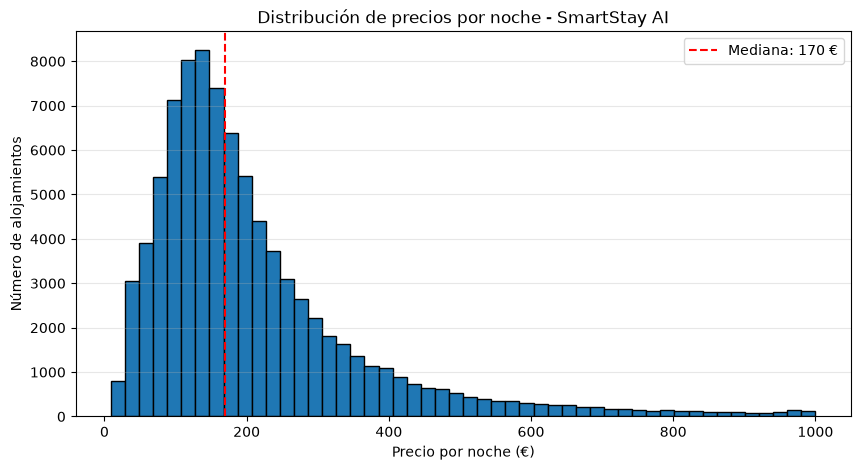

In [13]:
import matplotlib.pyplot as plt

# Solo para visualizar: precios entre 0 y 1000 €
precios = df["price"].dropna()
precios_grafico = precios[precios <= 1000]

plt.figure(figsize=(10, 5))

plt.hist(
    precios_grafico,
    bins=50,
    edgecolor="black"
)

plt.axvline(
    precios.median(),
    color="red",
    linestyle="--",
    label=f"Mediana: {precios.median():.0f} €"
)

plt.title("Distribución de precios por noche - SmartStay AI")
plt.xlabel("Precio por noche (€)")
plt.ylabel("Número de alojamientos")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

### Gráfico 1. Histograma de distribución de precios

El histograma representa la distribución de los precios anunciados por noche de los alojamientos turísticos incluidos en SmartStay AI.

Para facilitar su interpretación, se muestran únicamente los alojamientos con precios iguales o inferiores a 1.000 €, que representan aproximadamente el 97,34 % de los registros con precio conocido.

**Observaciones:**

- La mayor concentración de alojamientos se encuentra aproximadamente entre 80 € y 250 € por noche.
- La mediana del precio es de **170 €**.
- La media es de **264,05 €**, superior a la mediana.
- La distribución presenta una **asimetría positiva**, con una cola prolongada hacia los precios elevados.
- Existen valores extremos que alcanzan los **110.700 €**, aunque no aparecen en este gráfico.

**Conclusión:**

La distribución de precios no es simétrica y está influida por alojamientos con precios excepcionalmente elevados.

Este comportamiento deberá tenerse en cuenta durante el preprocesamiento y entrenamiento de los modelos de regresión. Se estudiará el tratamiento de los valores atípicos y la posible transformación logarítmica de la variable objetivo.

La limitación a 1.000 € se aplica únicamente a la visualización; no se han eliminado registros del dataset original.

### Gráfico de caja (boxplot)

C:\Users\Jon.Gorricho\AppData\Local\Temp\ipykernel_20116\2227360242.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


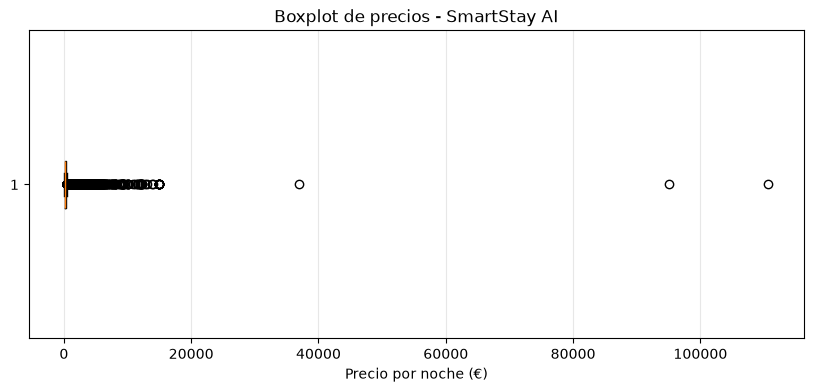

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.boxplot(
    df["price"].dropna(),
    vert=False
)

plt.title("Boxplot de precios - SmartStay AI")
plt.xlabel("Precio por noche (€)")
plt.grid(axis="x", alpha=0.3)

plt.show()

### Gráfico 2. Boxplot de precios

El diagrama de caja muestra la dispersión de los precios anunciados por noche, incluyendo todos los registros con precio conocido.

**Observaciones:**

- La mediana es de **170 €**.
- El primer cuartil (Q1) es **114 €**.
- El tercer cuartil (Q3) es **268 €**.
- El rango intercuartílico (IQR) es **154 €**.
- Aplicando el criterio de 1,5 × IQR, el límite superior de valores atípicos es **499 €**.
- Se observan valores extremos de **36.883 €, 95.042 € y 110.700 €**.

**Conclusión:**

El gráfico confirma la existencia de numerosos valores atípicos superiores al rango habitual de precios.

Estos valores comprimen visualmente la caja y dificultan la interpretación de la distribución central.

Los valores atípicos estadísticos no se consideran automáticamente errores. Su tratamiento se decidirá durante el preprocesamiento y se evaluará su impacto sobre el rendimiento de los modelos predictivos.

# Boxplot mostrando únicamente los precios hasta 1.000 €.

C:\Users\Jon.Gorricho\AppData\Local\Temp\ipykernel_20116\2902096734.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


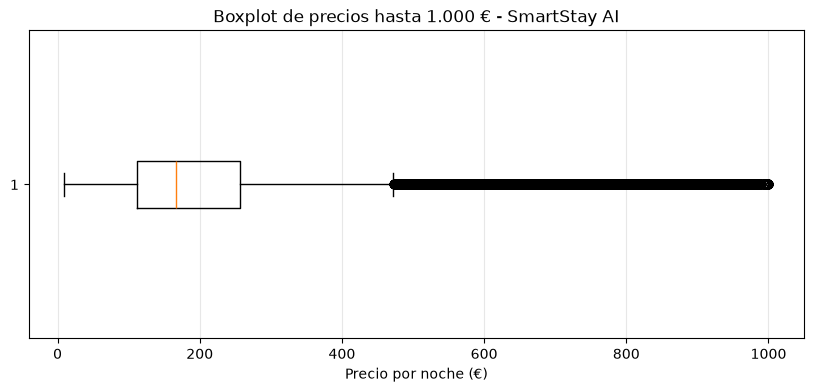

In [15]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    df.loc[df["price"] <= 1000, "price"].dropna(),
    vert=False
)

plt.title("Boxplot de precios hasta 1.000 € - SmartStay AI")
plt.xlabel("Precio por noche (€)")
plt.grid(axis="x", alpha=0.3)

plt.show()

### Gráfico 2. Boxplot de precios hasta 1.000 €

Para mejorar la visualización del diagrama de caja, se ha generado una segunda representación limitada a alojamientos con precios iguales o inferiores a 1.000 €.

**Observaciones:**

- La caja permite identificar claramente el rango central de precios.
- La mediana se sitúa aproximadamente en 170 €.
- Se observa una concentración importante de precios en los valores bajos y medios.
- Aparecen numerosos valores atípicos por encima del bigote superior.
- La distribución presenta asimetría positiva.

**Conclusión:**

La nueva visualización confirma que la mayor parte de los alojamientos tiene precios relativamente concentrados, mientras que existe un conjunto de anuncios considerablemente más caros.

La limitación a 1.000 € se ha utilizado únicamente para facilitar la interpretación gráfica. No se han eliminado registros del dataset original.

### Gráfico 3: barras por zona

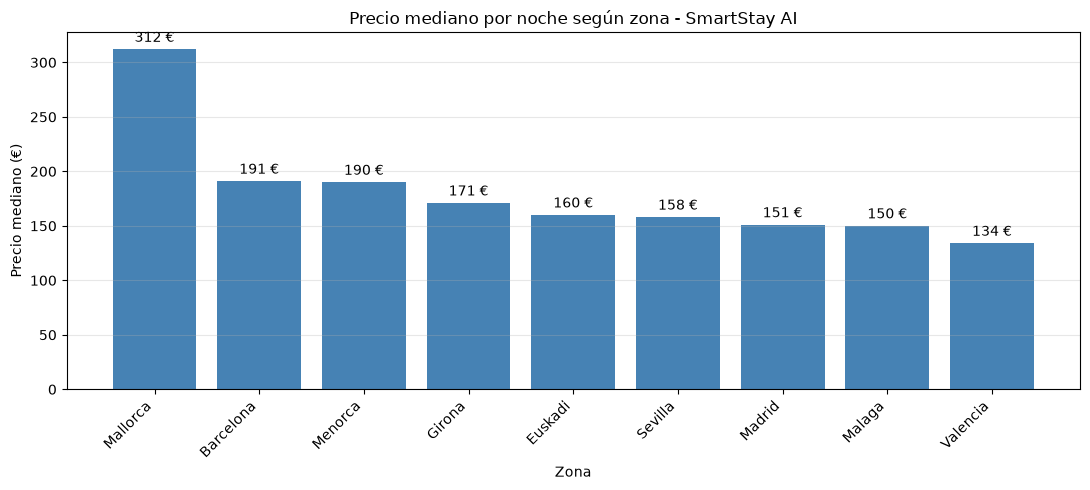

In [16]:
# Precio mediano por zona
precio_zona = (
    df.groupby("zona")["price"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 5))

barras = plt.bar(
    precio_zona.index,
    precio_zona.values,
    color="steelblue"
)

plt.bar_label(barras, fmt="%.0f €", padding=3)

plt.title("Precio mediano por noche según zona - SmartStay AI")
plt.xlabel("Zona")
plt.ylabel("Precio mediano (€)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

### Gráfico 3. Comparación de precios medianos por zona

Se ha calculado el precio mediano por noche de los alojamientos turísticos para las nueve zonas geográficas incluidas en SmartStay AI.

Se utiliza la mediana en lugar de la media para reducir la influencia de los valores extremos detectados anteriormente.

**Resultados principales:**

- **Mallorca:** 312 € por noche, la mediana más elevada.
- **Barcelona:** 191 €.
- **Menorca:** 190 €.
- **Girona:** 171 €.
- **Euskadi:** 160 €.
- **Sevilla:** 158 €.
- **Madrid:** 151 €.
- **Málaga:** 150 €.
- **Valencia:** 134 €, la mediana más baja.

**Conclusión:**

Se observan diferencias significativas en términos descriptivos entre las zonas geográficas, especialmente entre Mallorca y Valencia.

La mediana de Mallorca es aproximadamente 2,33 veces la de Valencia.

Estos resultados sugieren que la ubicación geográfica puede ser una variable predictora relevante para estimar el precio anunciado por noche.

No obstante, será necesario analizar otras características, como el tipo de alojamiento, para determinar si parte de estas diferencias se explica por la composición de la oferta.

### 4 . Gráfico de dispersión (scatter plot)

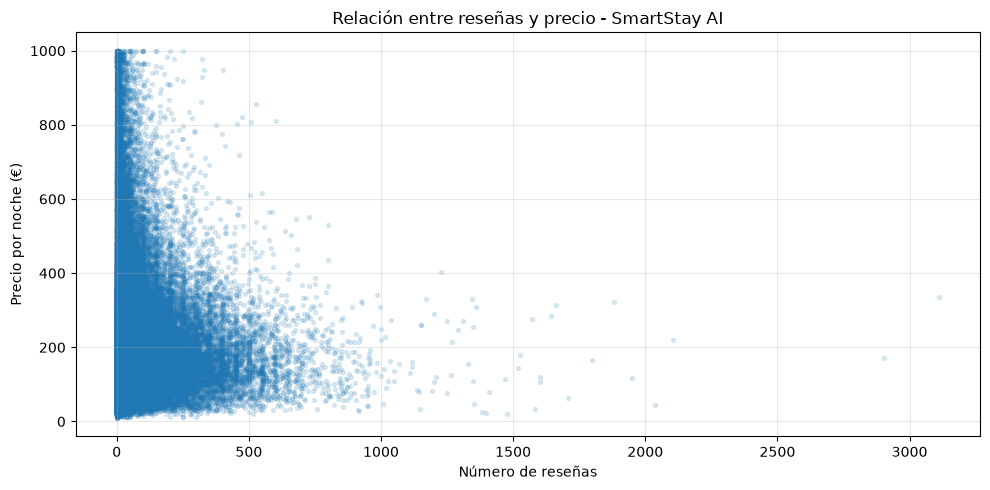

In [17]:
# Gráfico 4: relación entre reseñas y precio

datos_scatter = df[
    (df["price"].notna()) &
    (df["price"] <= 1000)
]

plt.figure(figsize=(10, 5))

plt.scatter(
    datos_scatter["number_of_reviews"],
    datos_scatter["price"],
    alpha=0.15,
    s=8
)

plt.title("Relación entre reseñas y precio - SmartStay AI")
plt.xlabel("Número de reseñas")
plt.ylabel("Precio por noche (€)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Gráfico 4. Relación entre número de reseñas y precio

Se ha generado un gráfico de dispersión para analizar la relación entre el número total de reseñas (`number_of_reviews`) y el precio anunciado por noche (`price`).

Para mejorar la visualización se han utilizado los alojamientos con precios iguales o inferiores a 1.000 €.

**Observaciones:**

- La mayoría de los alojamientos presenta un número relativamente reducido de reseñas.
- Los alojamientos con pocas reseñas muestran una gran variabilidad de precios.
- Los anuncios con un número elevado de reseñas parecen concentrarse en rangos de precios más moderados.
- No se aprecia una relación lineal positiva clara entre el número de reseñas y el precio.

**Conclusión:**

El número de reseñas, por sí solo, no parece suficiente para explicar el precio de un alojamiento.

La relación podría depender de otras variables, como la ubicación, el tipo de alojamiento o la antigüedad del anuncio.

Se calcularán las correlaciones entre variables numéricas para estudiar estas relaciones con mayor precisión.

La limitación de precios a 1.000 € se aplica exclusivamente a la visualización.

### Gráfico 5:  mapa de calor de correlaciones

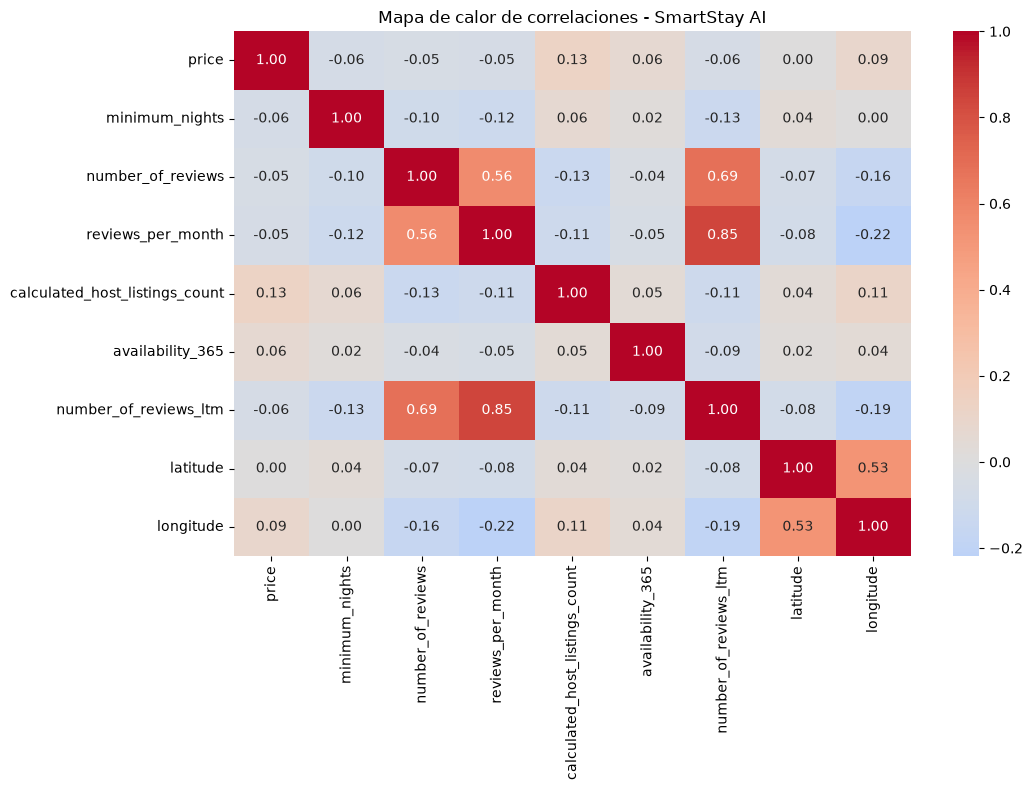

In [18]:
# Gráfico 5: mapa de calor de correlaciones

columnas = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "number_of_reviews_ltm",
    "latitude",
    "longitude"
]

# Correlación de Pearson
correlaciones = df[columnas].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlaciones,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Mapa de calor de correlaciones - SmartStay AI")
plt.tight_layout()
plt.show()

### Gráfico 5. Mapa de calor de correlaciones

Se ha generado una matriz de correlación de Pearson para analizar las relaciones lineales entre las principales variables numéricas del dataset.

**Relación con el precio (`price`):**

- `calculated_host_listings_count`: correlación de **+0,13**.
- `longitude`: correlación de **+0,09**.
- `availability_365`: correlación de **+0,06**.
- `number_of_reviews`: correlación de **−0,05**.
- `reviews_per_month`: correlación de **−0,05**.
- `minimum_nights`: correlación de **−0,06**.
- `number_of_reviews_ltm`: correlación de **−0,06**.
- `latitude`: correlación próxima a **0,00**.

Ninguna de las variables numéricas analizadas presenta una correlación lineal fuerte con el precio.

**Relaciones entre variables predictoras:**

Se identifican correlaciones destacadas entre las variables relacionadas con reseñas:

- `reviews_per_month` y `number_of_reviews_ltm`: **+0,85**.
- `number_of_reviews` y `number_of_reviews_ltm`: **+0,69**.
- `number_of_reviews` y `reviews_per_month`: **+0,56**.

Estas relaciones indican que algunas variables contienen información parcialmente redundante.

**Conclusión:**

Las variables numéricas, consideradas individualmente, muestran una relación lineal débil con el precio anunciado por noche.

Sin embargo, esto no implica que carezcan de capacidad predictiva. La relación podría ser no lineal o depender de combinaciones de características.

Además, las variables categóricas, como la zona geográfica, el barrio y el tipo de alojamiento, podrían aportar información relevante.

Se tendrá en cuenta la presencia de valores extremos, que pueden afectar al cálculo de Pearson, y se estudiará la utilidad de las variables durante el entrenamiento de los modelos.

### Analizar los tipos de alojamiento

In [19]:
# Distribución de tipos de alojamiento
print("Número de alojamientos por tipo:")
display(df["room_type"].value_counts())

# Precio mediano por tipo de alojamiento
print("Precio mediano por tipo de alojamiento:")
display(
    df.groupby("room_type")["price"]
    .median()
    .sort_values(ascending=False)
)

Número de alojamientos por tipo:


room_type
Entire home/apt    89983
Private room       18760
Shared room          426
Hotel room           268
Name: count, dtype: int64

Precio mediano por tipo de alojamiento:


room_type
Hotel room        206.00
Entire home/apt   186.00
Private room       82.00
Shared room        40.00
Name: price, dtype: float64

### Análisis del precio mediano por tipo de alojamiento

Se ha calculado el precio mediano por noche para cada categoría de la variable `room_type`.

| Tipo de alojamiento | Precio mediano |
|---|---:|
| Habitación de hotel | 206 € |
| Vivienda completa | 186 € |
| Habitación privada | 82 € |
| Habitación compartida | 40 € |

**Observaciones:**

- Las habitaciones de hotel presentan la mediana más elevada, con 206 € por noche.
- Las viviendas completas tienen un precio mediano de 186 €, aproximadamente 2,27 veces el de las habitaciones privadas.
- Las habitaciones compartidas presentan el precio mediano más bajo, con 40 €.
- Las categorías de habitaciones de hotel y compartidas tienen una representación reducida en el dataset.

**Conclusión:**

Se observan diferencias importantes en los precios anunciados según el tipo de alojamiento.

Estos resultados sugieren que `room_type` es una variable categórica potencialmente relevante para la predicción del precio.

Durante el entrenamiento se utilizará una codificación adecuada para incorporar esta variable a los modelos de aprendizaje automático.

## 6. Análisis y tratamiento de valores ausentes

Se estudian los patrones de ausencia por variable y se documentan las decisiones de tratamiento. El DataFrame de trabajo `df_clean` se crea en esta sección.


### Valores ausentes en `reviews_per_month`

In [20]:
# Relación entre ausencia de reseñas y reviews_per_month

sin_resenas = df[df["number_of_reviews"] == 0]

print("Alojamientos sin reseñas:", len(sin_resenas))

print(
    "Sin reseñas y reviews_per_month nulo:",
    sin_resenas["reviews_per_month"].isna().sum()
)

print(
    "Con reseñas y reviews_per_month nulo:",
    df.loc[
        df["number_of_reviews"] > 0,
        "reviews_per_month"
    ].isna().sum()
)

Alojamientos sin reseñas: 15841
Sin reseñas y reviews_per_month nulo: 15841
Con reseñas y reviews_per_month nulo: 0


### Análisis de valores ausentes en `reviews_per_month`

Se ha investigado la relación entre el número total de reseñas (`number_of_reviews`) y los valores ausentes de `reviews_per_month`.

**Resultados:**

| Comprobación | Registros |
|---|---:|
| Alojamientos sin reseñas | 15.841 |
| Sin reseñas y `reviews_per_month` nulo | 15.841 |
| Con reseñas y `reviews_per_month` nulo | 0 |

**Conclusión:**

Se ha comprobado que el 100 % de los valores ausentes de `reviews_per_month` corresponde a alojamientos sin reseñas.

Por tanto, se considera adecuado sustituir los valores ausentes de esta variable por **0**, interpretando que estos alojamientos no tienen reseñas mensuales registradas.

Esta estrategia permite conservar los registros y evita introducir valores artificiales mediante imputaciones basadas en la media o la mediana.

El tratamiento se aplicará sobre una copia de los datos, conservando el dataset original sin modificaciones.

### Sustituimos valores ausentes en `reviews_per_month`

In [21]:
# Crear una copia para el preprocesamiento
df_clean = df.copy()

# Sustituir valores ausentes por 0
df_clean["reviews_per_month"] = (
    df_clean["reviews_per_month"].fillna(0)
)

# Comprobar el resultado
print(
    "Nulos originales:",
    df["reviews_per_month"].isna().sum()
)

print(
    "Nulos después de imputar:",
    df_clean["reviews_per_month"].isna().sum()
)

print(
    "Registros conservados:",
    len(df_clean)
)

Nulos originales: 15841
Nulos después de imputar: 0
Registros conservados: 109437


In [22]:
# Análisis de minimum_nights

print("Valores ausentes:",
      df_clean["minimum_nights"].isna().sum())

print("\nEstadísticas descriptivas:")
display(df_clean["minimum_nights"].describe())

print("\nValores más frecuentes:")
display(
    df_clean["minimum_nights"]
    .value_counts()
    .head(15)
)

Valores ausentes: 10745

Estadísticas descriptivas:


count   98692.00
mean        6.57
std        18.39
min         1.00
25%         1.00
50%         2.00
75%         4.00
max      1125.00
Name: minimum_nights, dtype: float64


Valores más frecuentes:


minimum_nights
1.00     41731
2.00     20651
3.00      8824
4.00      4139
31.00     4122
5.00      3889
7.00      3769
32.00     2997
30.00     2414
6.00      1311
11.00      990
10.00      874
28.00      457
60.00      436
15.00      336
Name: count, dtype: int64

### Tratamiento de valores ausentes en `minimum_nights`

La variable `minimum_nights` presenta **10.745 valores ausentes**, equivalentes al 9,82 % del dataset.

Se ha analizado su distribución mediante estadísticas descriptivas y frecuencias.

**Resultados principales:**

- Registros con dato disponible: 98.692.
- Media: 6,57 noches.
- Mediana: 2 noches.
- Primer cuartil: 1 noche.
- Tercer cuartil: 4 noches.
- Máximo: 1.125 noches.
- El 72,15 % de los registros con dato disponible exige entre 1 y 3 noches.

También se observa un grupo relevante de alojamientos con estancias mínimas de 30, 31 y 32 noches.

**Decisión de preprocesamiento:**

Se utilizará la imputación mediante la mediana para los valores ausentes de `minimum_nights`, ya que es una medida robusta frente a valores extremos.

La imputación se implementará mediante `SimpleImputer(strategy="median")` dentro del Pipeline de scikit-learn, ajustado exclusivamente con los datos de entrenamiento.

No se eliminarán los valores elevados de estancias mínimas sin realizar previamente un análisis adicional.

In [23]:
# Análisis de precios ausentes por zona

resumen_precio = df_clean.groupby("zona")["price"].agg(
    total="size",
    con_precio="count"
)

resumen_precio["sin_precio"] = (
    resumen_precio["total"] - resumen_precio["con_precio"]
)

resumen_precio["porcentaje_nulos"] = (
    resumen_precio["sin_precio"] /
    resumen_precio["total"] * 100
)

display(
    resumen_precio.sort_values(
        "porcentaje_nulos",
        ascending=False
    )
)

,total,con_precio,sin_precio,porcentaje_nulos
zona,,,,
Girona,20470,15136,5334,26.06
Mallorca,14901,11082,3819,25.63
Madrid,23109,18785,4324,18.71
Barcelona,15236,12610,2626,17.24
Menorca,3625,3013,612,16.88
Euskadi,6248,5540,708,11.33
Malaga,9505,8528,977,10.28
Valencia,7968,7197,771,9.68
Sevilla,8375,7723,652,7.79


### Análisis de valores ausentes en la variable objetivo `price`

La variable objetivo `price` presenta **19.823 valores ausentes**, equivalentes al **18,11 %** de los 109.437 alojamientos.

Se ha analizado la distribución de estos valores ausentes por zona geográfica.

| Zona | Registros sin precio | Porcentaje de nulos |
|---|---:|---:|
| Girona | 5.334 | 26,06 % |
| Mallorca | 3.819 | 25,63 % |
| Madrid | 4.324 | 18,71 % |
| Barcelona | 2.626 | 17,24 % |
| Menorca | 612 | 16,88 % |
| Euskadi | 708 | 11,33 % |
| Málaga | 977 | 10,28 % |
| Valencia | 771 | 9,68 % |
| Sevilla | 652 | 7,79 % |

**Observaciones:**

Los valores ausentes no se distribuyen de forma uniforme entre las zonas geográficas.

Girona y Mallorca presentan los porcentajes más elevados, superiores al 25 %, mientras que Sevilla registra el porcentaje más bajo, con un 7,79 %.

Esta diferencia podría afectar a la representatividad geográfica del conjunto utilizado para el entrenamiento.

**Decisión de preprocesamiento:**

No se imputarán los valores ausentes de `price`, porque esta variable constituye el objetivo del modelo de regresión.

Se utilizarán los **89.614 registros con precio conocido** para el entrenamiento y la evaluación de los modelos.

Los registros sin precio se conservarán por separado para posibles predicciones posteriores.

**Limitación:**

La ausencia desigual de precios entre zonas podría introducir sesgos de selección. Se tendrá en cuenta esta circunstancia al interpretar los resultados.

### Análisis neighbourhood_group

In [24]:
# Análisis de nulos de neighbourhood_group por zona

resumen_barrios = df_clean.groupby("zona")["neighbourhood_group"].agg(
    total="size",
    con_dato="count"
)

resumen_barrios["nulos"] = (
    resumen_barrios["total"] - resumen_barrios["con_dato"]
)

resumen_barrios["porcentaje_nulos"] = (
    resumen_barrios["nulos"] /
    resumen_barrios["total"] * 100
)

display(
    resumen_barrios.sort_values(
        "porcentaje_nulos",
        ascending=False
    )
)

,total,con_dato,nulos,porcentaje_nulos
zona,,,,
Girona,20470,0,20470,100.00
Menorca,3625,0,3625,100.00
Malaga,9505,0,9505,100.00
Mallorca,14901,0,14901,100.00
Barcelona,15236,15236,0,0.00
Madrid,23109,23109,0,0.00
Euskadi,6248,6248,0,0.00
Sevilla,8375,8375,0,0.00
Valencia,7968,7968,0,0.00


### Análisis de valores ausentes en `neighbourhood_group`

La variable `neighbourhood_group` presenta **48.501 valores ausentes**, equivalentes al **44,32 % del dataset**.

Se ha analizado su distribución por zona geográfica.

**Resultados:**

| Zona | Porcentaje de nulos |
|---|---:|
| Girona | 100 % |
| Mallorca | 100 % |
| Málaga | 100 % |
| Menorca | 100 % |
| Barcelona | 0 % |
| Madrid | 0 % |
| Euskadi | 0 % |
| Sevilla | 0 % |
| Valencia | 0 % |

**Observaciones:**

Los valores ausentes se concentran exclusivamente en cuatro zonas geográficas, mientras que las otras cinco presentan información completa.

Este patrón sugiere que la ausencia de datos podría estar relacionada con diferencias estructurales entre las fuentes originales.

**Decisión de preprocesamiento:**

Se excluirá inicialmente `neighbourhood_group` de las variables predictoras, debido a su elevado porcentaje de valores ausentes y a su disponibilidad desigual entre zonas.

Se conservarán otras características geográficas, como `zona`, `neighbourhood`, `latitude` y `longitude`.

La columna permanecerá en el dataset original y podrá reconsiderarse en experimentos posteriores.

### Análisis de license

In [25]:
# Análisis de nulos de license por zona

resumen_license = df_clean.groupby("zona")["license"].agg(
    total="size",
    con_dato="count"
)

resumen_license["nulos"] = (
    resumen_license["total"] - resumen_license["con_dato"]
)

resumen_license["porcentaje_nulos"] = (
    resumen_license["nulos"] /
    resumen_license["total"] * 100
)

display(
    resumen_license.sort_values(
        "porcentaje_nulos",
        ascending=False
    )
)

,total,con_dato,nulos,porcentaje_nulos
zona,,,,
Madrid,23109,12196,10913,47.22
Barcelona,15236,9770,5466,35.88
Valencia,7968,5112,2856,35.84
Sevilla,8375,6332,2043,24.39
Malaga,9505,7285,2220,23.36
Euskadi,6248,5128,1120,17.93
Girona,20470,17796,2674,13.06
Mallorca,14901,13853,1048,7.03
Menorca,3625,3444,181,4.99


### Análisis de valores ausentes en `license`

La variable `license` presenta **28.521 valores ausentes**, equivalentes al **26,06 % del dataset**.

Se ha analizado su distribución por zona geográfica.

| Zona | Porcentaje de nulos |
|---|---:|
| Madrid | 47,22 % |
| Barcelona | 35,88 % |
| Valencia | 35,84 % |
| Sevilla | 24,39 % |
| Málaga | 23,36 % |
| Euskadi | 17,93 % |
| Girona | 13,06 % |
| Mallorca | 7,03 % |
| Menorca | 4,99 % |

**Observaciones:**

La ausencia de información sobre licencias varía considerablemente entre las zonas.

Madrid presenta el porcentaje más elevado, mientras que Menorca registra el menor.

Un valor ausente no permite concluir que un alojamiento carezca de licencia administrativa.

**Decisión de preprocesamiento:**

Se excluirá inicialmente `license` de las variables predictoras, debido a su elevado porcentaje de nulos y a que sus valores pueden representar identificadores administrativos de alta cardinalidad.

Como experimento posterior, se podrá evaluar una variable binaria que indique si la licencia está informada, sin atribuirle significado sobre la legalidad del alojamiento.

La columna original se conservará en el dataset.

### Análisis last_review

In [26]:
# Análisis de last_review

print("Tipo de dato:")
print(df_clean["last_review"].dtype)

print("\nValores ausentes:")
print(df_clean["last_review"].isna().sum())

print("\nEjemplos de fechas:")
display(df_clean["last_review"].dropna().head(10))

print("\nComprobación de nulos y reseñas:")
print(
    pd.crosstab(
        df_clean["last_review"].isna(),
        df_clean["number_of_reviews"] == 0,
        rownames=["Fecha ausente"],
        colnames=["Sin reseñas"]
    )
)

Tipo de dato:
str

Valores ausentes:
15841

Ejemplos de fechas:


0    2026-07-20
1    2026-09-07
2    2026-09-13
3    2023-12-13
4    2026-09-13
5    2026-01-02
6    2026-08-24
7    2011-06-23
8    2026-06-08
9    2025-04-17
Name: last_review, dtype: str


Comprobación de nulos y reseñas:
Sin reseñas    False  True 
Fecha ausente              
False          93596      0
True               0  15841


### Análisis de valores ausentes en `last_review`

La variable `last_review` presenta **15.841 valores ausentes**, equivalentes al **14,47 % del dataset**.

Las fechas están representadas como texto con formato `AAAA-MM-DD`.

Se ha comprobado su relación con la variable `number_of_reviews`.

**Resultados:**

- 93.596 alojamientos tienen reseñas y fecha de última reseña.
- 15.841 alojamientos no tienen reseñas ni fecha.
- No existen alojamientos con reseñas y fecha ausente.
- No existen alojamientos sin reseñas que tengan fecha informada.

**Conclusión:**

Los valores ausentes de `last_review` están asociados a la ausencia de reseñas y presentan una explicación coherente con el significado de la variable.

**Decisión de preprocesamiento:**

No se imputarán fechas ficticias.

Se estudiará la transformación de `last_review` en una característica numérica que represente los días transcurridos desde la última reseña hasta una fecha de referencia válida.

Los alojamientos sin reseñas se identificarán mediante una variable indicadora y sus valores ausentes se tratarán dentro del Pipeline.

La columna original se conservará en el dataset.

### Comprobar las fechas

In [27]:
# Convertir fechas sin modificar la columna original

fechas = pd.to_datetime(
    df_clean["last_review"],
    errors="coerce"
)

print("Fechas válidas:", fechas.notna().sum())

print("Fechas ausentes o inválidas:", fechas.isna().sum())

print("Fecha más antigua:", fechas.min())

print("Fecha más reciente:", fechas.max())

print(
    "Fechas con formato inválido:",
    (df_clean["last_review"].notna() & fechas.isna()).sum()
)

Fechas válidas: 93596
Fechas ausentes o inválidas: 15841
Fecha más antigua: 2011-06-23 00:00:00
Fecha más reciente: 2026-10-01 00:00:00
Fechas con formato inválido: 0


### Validación temporal de `last_review`

Se ha realizado una conversión de la variable `last_review` a formato `datetime` mediante `pd.to_datetime()`.

**Resultados:**

- Fechas válidas: 93.596.
- Valores ausentes: 15.841.
- Fechas con formato inválido: 0.
- Fecha más antigua: 23/06/2011.
- Fecha más reciente: 01/10/2026.

**Conclusiones:**

Todas las fechas informadas presentan un formato válido.

Los valores ausentes coinciden exactamente con los alojamientos que no han recibido reseñas.

No se considera necesario eliminar registros ni imputar fechas ficticias.

**Tratamiento previsto:**

Durante el preprocesamiento se evaluará la creación de una variable numérica denominada `dias_desde_ultima_resena`, calculada respecto a una fecha de referencia coherente con la extracción de los datos.

Esta transformación permitirá incorporar información temporal a los modelos de Machine Learning.

### Comprobar si quedan más valores nulos.

In [28]:
# Resumen actualizado de valores ausentes

resumen_nulos = pd.DataFrame({
    "nulos": df_clean.isna().sum(),
    "porcentaje": (
        df_clean.isna().mean() * 100
    ).round(2)
})

display(
    resumen_nulos[
        resumen_nulos["nulos"] > 0
    ].sort_values("porcentaje", ascending=False)
)

,nulos,porcentaje
neighbourhood_group,48501,44.32
license,28521,26.06
price,19823,18.11
last_review,15841,14.47
minimum_nights,10745,9.82


### Conclusiones del análisis de valores ausentes

Se ha completado el análisis de valores ausentes del dataset SmartStay AI, compuesto por 109.437 alojamientos.

Se han identificado seis variables con valores ausentes en el dataset original.

**Decisiones adoptadas:**

- `reviews_per_month`: imputación con cero, al comprobarse que sus valores ausentes corresponden a alojamientos sin reseñas.
- `minimum_nights`: imputación mediante la mediana, dentro del Pipeline de entrenamiento.
- `price`: exclusión de los registros sin precio del conjunto supervisado.
- `neighbourhood_group`: exclusión inicial como variable predictora por su disponibilidad desigual entre zonas.
- `license`: exclusión inicial como variable predictora por sus valores ausentes y su carácter administrativo.
- `last_review`: transformación temporal pendiente, sin imputación de fechas ficticias.

Se conservará el dataset original y se aplicarán las transformaciones necesarias para preparar los modelos predictivos.

**Resultado:** existen 89.614 registros con precio conocido, disponibles para la fase de modelado antes de realizar las particiones de entrenamiento y prueba.

## 7. Preparación del dataset para Machine Learning

Se excluyen las filas sin variable objetivo y se examinan las variables categóricas antes de definir los predictores.


### Exclusión de registros sin precio objetivo

Una vez completado el análisis exploratorio y la revisión de valores ausentes, se prepara el conjunto de datos para entrenar modelos de regresión capaces de predecir el precio de los alojamientos.

La variable objetivo será `price`.

Se conservarán únicamente los registros que tengan un precio conocido, ya que los modelos supervisados necesitan disponer del valor real de la variable objetivo durante el entrenamiento.

No se imputarán precios artificiales.

El dataset original permanecerá intacto y las transformaciones posteriores se realizarán sobre una copia independiente.

In [29]:
# Crear dataset para Machine Learning

df_ml = df_clean.dropna(subset=["price"]).copy()

print("Dataset original:", df_clean.shape)
print("Dataset para ML:", df_ml.shape)
print("Precios ausentes:", df_ml["price"].isna().sum())

Dataset original: (109437, 20)
Dataset para ML: (89614, 20)
Precios ausentes: 0


### Primera comprobación: cardinalidad de las variables categóricas

In [30]:
# Comprobar cardinalidad de variables categóricas

columnas_categoricas = df_ml.select_dtypes(
    include=["object", "str", "category"]
).columns

cardinalidad = (
    df_ml[columnas_categoricas]
    .nunique()
    .sort_values(ascending=False)
)

display(cardinalidad)

name                   83962
license                56008
host_name              10564
last_review             1993
neighbourhood            867
neighbourhood_group       64
zona                       9
room_type                  4
dtype: int64

## 8. Ingeniería de características

Se construye y valida la variable `estancia_larga` a partir de `minimum_nights`.


### Feature engineering: crear estancia_larga

In [31]:
# Ingeniería de características: estancia larga

df_ml["estancia_larga"] = (
    df_ml["minimum_nights"]
    .ge(30)
    .astype("Int64")
    .mask(df_ml["minimum_nights"].isna())
)

print("Distribución de estancia_larga:")
display(df_ml["estancia_larga"].value_counts(dropna=False))

Distribución de estancia_larga:


estancia_larga
0       71835
<NA>     9717
1        8062
Name: count, dtype: Int64

In [32]:
# Comprobar coherencia de estancia_larga

print("Nulos en minimum_nights:",
      df_ml["minimum_nights"].isna().sum())

print("Nulos en estancia_larga:",
      df_ml["estancia_larga"].isna().sum())

print("Incoherencias entre ambas variables:",
      (
          df_ml["minimum_nights"].notna()
          & df_ml["estancia_larga"].notna()
          & (
              df_ml["estancia_larga"]
              != df_ml["minimum_nights"].ge(30).astype("Int64")
          )
      ).sum())

Nulos en minimum_nights: 9717
Nulos en estancia_larga: 9717
Incoherencias entre ambas variables: 0



### Validación de la variable `estancia_larga`

Se ha comprobado la coherencia de la variable creada mediante ingeniería de características.

**Resultados:**
- Valores nulos en `minimum_nights`: 9.717.
- Valores nulos en `estancia_larga`: 9.717.
- Incoherencias detectadas: 0.

La variable `estancia_larga` identifica correctamente los alojamientos cuya estancia mínima es igual o superior a 30 noches.

Los valores desconocidos se conservan como ausentes para evitar clasificarlos incorrectamente.

**Conclusión:** la transformación es coherente antes de la imputación y puede utilizarse en el entrenamiento. La imputación posterior de ambas variables se realiza de forma independiente, lo que constituye una limitación metodológica que deberá tenerse en cuenta.

## 9. Selección de variables predictoras


### Selección de características para Machine Learning

Para el entrenamiento se seleccionan **11 variables predictoras: ocho numéricas y tres categóricas**.

Las variables numéricas son `latitude`, `longitude`, `minimum_nights`, `number_of_reviews`, `reviews_per_month`, `calculated_host_listings_count`, `availability_365` y `number_of_reviews_ltm`.

Las variables categóricas son `zona`, `room_type` y `estancia_larga`.

La variable objetivo es `price`, correspondiente al precio anunciado por noche.

Se excluyen identificadores, nombres, licencias y otras variables que no se utilizan en el modelo, según las justificaciones del diccionario de variables.

Esta selección se mantiene en el notebook de modelos y en la aplicación Streamlit.

In [33]:
# Selección de variables predictoras

variables_numericas = [
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "number_of_reviews_ltm"
]

variables_categoricas = ["zona", "room_type", "estancia_larga"]

# Características y variable objetivo
X = df_ml[variables_numericas + variables_categoricas].copy()
y = df_ml["price"].copy()

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nVariables predictoras:")
display(X.head())

print("\nValores ausentes en X:")
display(X.isna().sum())

Dimensiones de X: (89614, 11)
Dimensiones de y: (89614,)

Variables predictoras:


,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,zona,room_type,estancia_larga
0,41.41,2.17,1.00,60,0.37,21,162,8,Barcelona,Entire home/apt,0
1,41.41,2.22,3.00,102,0.54,1,128,11,Barcelona,Entire home/apt,0
2,41.38,2.18,1.00,314,1.62,2,316,43,Barcelona,Entire home/apt,0
3,41.38,2.19,31.00,108,0.59,1,77,0,Barcelona,Private room,1
4,41.40,2.17,1.00,464,2.50,5,283,62,Barcelona,Entire home/apt,0



Valores ausentes en X:


latitude                             0
longitude                            0
minimum_nights                    9717
number_of_reviews                    0
reviews_per_month                    0
calculated_host_listings_count       0
availability_365                     0
number_of_reviews_ltm                0
zona                                 0
room_type                            0
estancia_larga                    9717
dtype: int64

### 10. División y guardado de los datos

Se separan entrenamiento y prueba y se exportan los cuatro ficheros que utilizará el notebook de modelos.


### División del dataset en entrenamiento y prueba

Se divide el dataset en dos subconjuntos mediante `train_test_split` de scikit-learn:

- 80 % para entrenamiento.
- 20 % para prueba.

Se utiliza `random_state=42` para garantizar la reproducibilidad.

El conjunto de prueba se reservará para la evaluación final de los modelos, evitando utilizarlo durante el ajuste de hiperparámetros o la selección de características.

Las transformaciones de imputación, escalado y codificación categórica se ajustarán exclusivamente con los datos de entrenamiento mediante Pipelines.

In [34]:
from sklearn.model_selection import train_test_split

# División entrenamiento / prueba

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nNulos en minimum_nights:")
print("Entrenamiento:", X_train["minimum_nights"].isna().sum())
print("Prueba:", X_test["minimum_nights"].isna().sum())

X_train: (71691, 11)
X_test: (17923, 11)
y_train: (71691,)
y_test: (17923,)

Nulos en minimum_nights:
Entrenamiento: 7791
Prueba: 1926


### Guardar los cuatro conjuntos

In [35]:
from pathlib import Path

# Carpeta de datos procesados
ruta = Path("../data/processed")
ruta.mkdir(parents=True, exist_ok=True)

# Guardar entrenamiento
X_train.to_csv(ruta / "X_train.csv", index=False)
y_train.to_frame(name="price").to_csv(
    ruta / "y_train.csv", index=False
)

# Guardar prueba
X_test.to_csv(ruta / "X_test.csv", index=False)
y_test.to_frame(name="price").to_csv(
    ruta / "y_test.csv", index=False
)

# Comprobar archivos
for archivo in sorted(ruta.glob("*.csv")):
    print(f"{archivo.name}: {archivo.stat().st_size / 1024:.1f} KB")

X_test.csv: 1206.7 KB
X_train.csv: 4830.1 KB
y_test.csv: 119.6 KB
y_train.csv: 478.8 KB


## 11. Conclusiones del análisis exploratorio

El análisis exploratorio del dataset de SmartStay AI ha permitido identificar las principales características de los alojamientos turísticos y preparar los datos para el entrenamiento de modelos de regresión.

### Principales hallazgos

1. **Distribución de precios:** los precios presentan una distribución asimétrica hacia la derecha, con alojamientos de precios muy elevados que pueden afectar al entrenamiento y a las métricas de los modelos.

2. **Diferencias geográficas:** existen diferencias de precio entre las distintas zonas analizadas, por lo que la ubicación es una característica relevante para la predicción.

3. **Tipo de alojamiento:** la variable `room_type` permite distinguir diferentes modalidades de alojamiento y aporta información útil para estimar el precio.

4. **Valores ausentes:** se han identificado valores nulos en distintas columnas. Su tratamiento se ha decidido teniendo en cuenta el significado de las variables y los patrones observados.

5. **Ingeniería de características:** se ha creado `estancia_larga` a partir de `minimum_nights`, para distinguir los alojamientos que requieren estancias mínimas de 30 noches o más.

### Preparación para Machine Learning

Se han seleccionado 11 variables predictoras y la variable objetivo `price`.

El conjunto de datos se ha dividido en entrenamiento (80 %) y test (20 %), reservando este último para evaluar el modelo seleccionado.

### Limitaciones

La presencia de valores extremos, la heterogeneidad entre zonas y los valores ausentes pueden influir en la precisión de las predicciones.

Además, los datos reflejan precios anunciados, que no necesariamente coinciden con los precios finales de las reservas.

### Continuidad del proyecto

Los datos preparados se utilizarán en `02_modelos.ipynb` para entrenar, comparar y seleccionar los modelos predictivos de SmartStay AI.
